In [1]:
from pathlib import Path

import pandas as pd

PASTA = Path("../dados/processados")

tomografos = pd.read_parquet(PASTA / "tomografos_cnes_24.parquet")
mapa = pd.read_parquet(PASTA / "municipio_regiao_saude.parquet")
pop = pd.read_parquet(PASTA / "populacao_sc_2024.parquet")

print("Tomógrafos:", tomografos.shape)
print("Mapa município-região:", mapa.shape)
print("População:", pop.shape)

Tomógrafos: (3577, 8)
Mapa município-região: (943, 2)
População: (295, 4)


In [2]:
mapa["CODUFMUN"] = mapa["CODUFMUN"].astype(str).str.strip()
mapa["REGSAUDE"] = mapa["REGSAUDE"].astype(str).str.strip()

print("Municípios no mapa:", mapa["CODUFMUN"].nunique())
print("Regiões de saúde:", sorted(mapa["REGSAUDE"].unique()))

# Algum município aparece em mais de uma região?
duplicados = mapa.groupby("CODUFMUN")["REGSAUDE"].nunique()
print("Municípios com mais de uma região:", (duplicados > 1).sum())

Municípios no mapa: 295
Regiões de saúde: ['', ',', '0', '0000', '0001', '0002', '0003', '0004', '0006', '0008', '0009', '001', '0011', '0013', '0017', '0018', '002', '003', '004', '005', '006', '007', '008', '009', '01', '010', '011', '012', '013', '016', '017', '018', '019', '02', '023', '024', '025', '03', '035', '04', '04ª', '05', '06', '07', '08', '09', '1', '10', '10ª', '10º', '11', '11º', '12', '12ª', '12°', '12º', '13', '13ª', '14', '14§', '14ª', '15', '16', '16ª', '17', '17ª', '18', '18R', '18ª', '18º', '19', '1ª', '1°', '2', '20', '20ª', '20ªG', '20º', '21', '21ª', '21º', '22', '22ª', '22º', '23', '23ª', '23º', '24', '24ª', '25', '25A', '25A.', '25ª', '26', '264', '267', '26ª', '27', '28', '29', '29ª', '29º', '2ª', '2º', '3', '31', '31º', '33', '33ª', '34', '35', '36', '36º', '3ª', '3º', '4', '4207', '4210', '4ª', '4°', '5', '5.ª', '5.º', '5ª', '5º', '6', '6ª', '7', '7ª', '8', '8ª', '8º', '9', '9 G', '9G', '9ª', '9ª G', '9¬', '9º G', 'IV', 'R14', 'X', 'XANX', 'XXE']
Município

In [3]:
from ftplib import FTP

ftp = FTP("ftp.datasus.gov.br", timeout=120)
ftp.login()

for pasta in ["/territorio", "/territorio/tabelas"]:
    try:
        ftp.cwd(pasta)
        print(f"=== {pasta} ===")
        print(ftp.nlst())
    except Exception as erro:
        print(f"{pasta}: {erro}")

ftp.quit()

=== /territorio ===
['2014-07-05', '2015-01-19', '2015-02-10', '2015-07-10', 'Atualizacoes_DTB-2015.xlsx', 'conversoes', 'doc', 'mapas', 'tabelas']
=== /territorio/tabelas ===
['2023', '2024', '2025', '2026']


'221 Goodbye.'

In [4]:
from ftplib import FTP

ftp = FTP("ftp.datasus.gov.br", timeout=120)
ftp.login()

for pasta in ["/territorio/tabelas/2024", "/territorio/tabelas/2025"]:
    ftp.cwd(pasta)
    print(f"=== {pasta} ===")
    print(ftp.nlst())

ftp.quit()

=== /territorio/tabelas/2024 ===
['02-base_territorio_fev24.zip', '03-base_territorial_mar.zip', '04-base_territorial_abr.zip', '05-base_territorial_mai24.zip', '06-base_territorial_jun24.zip', '07-base_territorial_jul24.zip', '08-base_territorial_ago24.zip', '09-base_territorial_set24.zip', '10-base_territorial_out24.zip', '11-base territorial_nov24.zip', '12-base territorial_dez24.zip']
=== /territorio/tabelas/2025 ===
['01-base_territorial_jan25.zip', '02-base_territorial_fev25.zip', '03-base_territorial_mar25.zip', '04-base_territorial_abr25.zip', '09-base_territorial_set25.zip', '10-base_territorial_out25.zip']


'221 Goodbye.'

In [5]:
import zipfile
from ftplib import FTP
from pathlib import Path

pasta_territorio = Path("../dados/brutos/territorio")
pasta_territorio.mkdir(parents=True, exist_ok=True)

nome = "12-base territorial_dez24.zip"
destino = pasta_territorio / nome

# Baixa o zip
ftp = FTP("ftp.datasus.gov.br", timeout=120)
ftp.login()
ftp.cwd("/territorio/tabelas/2024")
with open(destino, "wb") as arquivo:
    ftp.retrbinary(f"RETR {nome}", arquivo.write)
ftp.quit()

# Descompacta e lista o conteúdo
with zipfile.ZipFile(destino) as zip_ref:
    zip_ref.extractall(pasta_territorio)
    for item in zip_ref.namelist():
        print(item)

rl_municip_dsei.dbf
rl_municip_dsei.txt
rl_municip_dsei.xml
rl_municip_dsei_layout.txt
rl_municip_macsaud.csv
rl_municip_macsaud.dbf
rl_municip_macsaud.txt
rl_municip_macsaud.xml
rl_municip_macsaud_layout.txt
rl_municip_micibge.csv
rl_municip_micibge.dbf
rl_municip_micibge.txt
rl_municip_micibge.xml
rl_municip_micibge_layout.txt
rl_municip_pndr.csv
rl_municip_pndr.dbf
rl_municip_pndr.txt
rl_municip_pndr.xml
rl_municip_pndr_layout.txt
rl_municip_regmetr.csv
rl_municip_regmetr.dbf
rl_municip_regmetr.txt
rl_municip_regmetr.xml
rl_municip_regmetr_layout.txt
rl_municip_regsaud.csv
rl_municip_regsaud.dbf
rl_municip_regsaud.txt
rl_municip_regsaud.xml
rl_municip_regsaud_layout.txt
rl_municip_terrcid.csv
rl_municip_terrcid.dbf
rl_municip_terrcid.txt
rl_municip_terrcid.xml
rl_municip_terrcid_layout.txt
rl_regsaud_macsaud.csv
rl_regsaud_macsaud.dbf
rl_regsaud_macsaud.txt
rl_regsaud_macsaud.xml
rl_regsaud_macsaud_layout.txt
tb_divadm.csv
tb_divadm.dbf
tb_divadm.txt
tb_divadm.xml
tb_divadm_layout.t

In [6]:
pasta_territorio = Path("../dados/brutos/territorio")

# 1. Procura os arquivos ligados a regiões de saúde
print("Arquivos de região de saúde:")
for arquivo in sorted(pasta_territorio.glob("*regsaud*")):
    print(" ", arquivo.name)

# 2. Mostra o layout (descrição das colunas) da relação município-região
print()
print("=== Layout de rl_municip_regsaud ===")
print((pasta_territorio / "rl_municip_regsaud_layout.txt").read_text(encoding="latin-1"))

# 3. Mostra as primeiras linhas do CSV, sem interpretar, para ver o separador
print("=== Primeiras linhas de rl_municip_regsaud.csv ===")
with open(pasta_territorio / "rl_municip_regsaud.csv", encoding="latin-1") as arquivo:
    for _ in range(5):
        print(arquivo.readline().rstrip())

Arquivos de região de saúde:
  rl_municip_regsaud.csv
  rl_municip_regsaud.dbf
  rl_municip_regsaud.txt
  rl_municip_regsaud.xml
  rl_municip_regsaud_layout.txt
  rl_regsaud_macsaud.csv
  rl_regsaud_macsaud.dbf
  rl_regsaud_macsaud.txt
  rl_regsaud_macsaud.xml
  rl_regsaud_macsaud_layout.txt
  tb_regsaud.csv
  tb_regsaud.dbf
  tb_regsaud.txt
  tb_regsaud.xml
  tb_regsaud_layout.txt

=== Layout de rl_municip_regsaud ===
Coluna;Tamanho;Inicio;Fim;Tipo
CO_MUNICIP;6;1;6;CHAR
CO_REGSAUD;5;7;11;CHAR

=== Primeiras linhas de rl_municip_regsaud.csv ===
"CO_MUNICIP","CO_REGSAUD"
"110002","11001"
"110013","11001"
"110026","11001"
"110040","11001"


In [8]:
# 1. Lê as duas tabelas, tudo como texto
rel = pd.read_csv(pasta_territorio / "rl_municip_regsaud.csv", dtype=str)
nomes = pd.read_csv(pasta_territorio / "tb_regsaud.csv", dtype=str, encoding="utf-8")

# 2. Padroniza a tabela de nomes
nomes = nomes[nomes["CO_STATUS"] == "ATIVO"]
nomes = nomes.rename(columns={"REGSAUD": "CO_REGSAUD", "DS_NOME": "regiao_saude"})
nomes = nomes[["CO_REGSAUD", "regiao_saude"]]

# 3. Mantém só os municípios de SC (código começando com 42)
rel_sc = rel[rel["CO_MUNICIP"].str.startswith("42")]

# 4. Junta o nome da região a cada município
mapa_oficial = rel_sc.merge(nomes, on="CO_REGSAUD", how="left")

print("Municípios de SC:", mapa_oficial["CO_MUNICIP"].nunique())
print("Regiões de saúde de SC:", mapa_oficial["CO_REGSAUD"].nunique())
print("Municípios sem nome de região:", mapa_oficial["regiao_saude"].isna().sum())
print()
print(mapa_oficial.drop_duplicates("CO_REGSAUD")[["CO_REGSAUD", "regiao_saude"]].to_string(index=False))

Municípios de SC: 295
Regiões de saúde de SC: 17
Municípios sem nome de região: 0

CO_REGSAUD                   regiao_saude
     42001             Extremo Oeste - SC
     42002                     Oeste - SC
     42003                   Xanxerê - SC
     42004       Alto Vale do Itajaí - SC
     42005         Foz do Rio Itajaí - SC
     42006      Médio Vale do Itajaí - SC
     42007      Grande Florianópolis - SC
     42008                Meio Oeste - SC
     42009 Alto Vale do Rio do Peixe - SC
     42010  Alto Uruguai Catarinense - SC
     42011                  Nordeste - SC
     42012            Planalto Norte - SC
     42013         Serra Catarinense - SC
     42014   Extremo Sul Catarinense - SC
     42015               Carbonífera - SC
     42016                    Laguna - SC
     42017           Vale do Itapocú - SC


In [9]:
# 1. Ajusta e salva o mapa oficial
mapa_oficial["regiao_saude"] = mapa_oficial["regiao_saude"].str.replace(" - SC", "")
mapa_oficial = mapa_oficial.rename(columns={"CO_MUNICIP": "CODUFMUN"})
mapa_oficial.to_parquet(PASTA / "municipio_regiao_saude_oficial.parquet", index=False)

# 2. Tomógrafos de dezembro de 2024, com a região de cada estabelecimento
tc = tomografos.copy()
tc["COMPETEN"] = tc["COMPETEN"].astype(str).str.strip()
tc["CODUFMUN"] = tc["CODUFMUN"].astype(str).str.strip()

tc_dez = tc[tc["COMPETEN"] == "202412"].merge(mapa_oficial, on="CODUFMUN", how="left")
print("Estabelecimentos sem região:", tc_dez["regiao_saude"].isna().sum())

# Tomógrafos disponíveis ao SUS: só conta onde IND_SUS = 1
tc_dez["QT_SUS"] = tc_dez["QT_EXIST"].where(tc_dez["IND_SUS"] == 1, 0)

tc_regiao = tc_dez.groupby("regiao_saude")[["QT_EXIST", "QT_SUS"]].sum()

# 3. População por região
pop["CODUFMUN"] = pop["CODUFMUN"].astype(str)
pop_regiao = pop.merge(mapa_oficial, on="CODUFMUN").groupby("regiao_saude")["populacao"].sum()

# 4. Junta tudo e calcula as taxas
indicadores = tc_regiao.join(pop_regiao, how="right").fillna(0)
indicadores["tc_por_100mil"] = indicadores["QT_EXIST"] / indicadores["populacao"] * 100_000
indicadores["tc_sus_por_100mil"] = indicadores["QT_SUS"] / indicadores["populacao"] * 100_000
indicadores = indicadores.sort_values("tc_sus_por_100mil", ascending=False)

total = indicadores[["QT_EXIST", "QT_SUS", "populacao"]].sum()
print(f"SC: {total['QT_EXIST'] / total['populacao'] * 100_000:.2f} tomógrafos por 100 mil hab. "
      f"| {total['QT_SUS'] / total['populacao'] * 100_000:.2f} disponíveis ao SUS")

indicadores.round(2)

Estabelecimentos sem região: 0
SC: 4.08 tomógrafos por 100 mil hab. | 2.46 disponíveis ao SUS


,QT_EXIST,QT_SUS,populacao,tc_por_100mil,tc_sus_por_100mil
regiao_saude,,,,,
Alto Uruguai Catarinense,7,7,161118,4.34,4.34
Laguna,21,15,398784,5.27,3.76
Serra Catarinense,12,11,304468,3.94,3.61
Extremo Sul Catarinense,12,8,234389,5.12,3.41
Alto Vale do Rio do Peixe,13,9,296312,4.39,3.04
Meio Oeste,10,6,200134,5.00,3.00
Carbonífera,22,14,468509,4.70,2.99
Médio Vale do Itajaí,34,25,860457,3.95,2.91
Xanxerê,9,6,214722,4.19,2.79


In [10]:
nordeste = tc_dez[tc_dez["regiao_saude"] == "Nordeste"]
nordeste[["CNES", "CODUFMUN", "QT_EXIST", "QT_USO", "IND_SUS", "IND_NSUS"]].sort_values("QT_EXIST", ascending=False)

,CNES,CODUFMUN,QT_EXIST,QT_USO,IND_SUS,IND_NSUS
194,4886941,420910,3,3,0,1
197,7530137,420910,2,2,0,1
186,2521385,420910,1,1,0,1
185,2521296,420910,1,1,1,0
184,0070017,420910,1,1,0,1
188,2521431,420910,1,1,0,1
187,2521423,420910,1,1,0,1
191,2932474,420910,1,1,0,1
189,2622920,420910,1,1,0,1
192,4441753,420910,1,1,0,1


In [11]:
# 1. Junta os 12 meses em uma única tabela
sia = pd.concat(
    [pd.read_parquet(arquivo) for arquivo in sorted(PASTA.glob("tomografias_PASC24*.parquet"))],
    ignore_index=True,
)
for coluna in ["PA_CMP", "PA_CODUNI", "PA_UFMUN", "PA_MUNPCN", "PA_PROC_ID"]:
    sia[coluna] = sia[coluna].astype(str).str.strip()

print(f"Linhas: {len(sia):,}")
print(f"Total de tomografias SUS em SC em 2024: {int(sia['PA_QTDAPR'].sum()):,}")
print(f"Valor aprovado: R$ {sia['PA_VALAPR'].sum():,.2f}")

# 2. Exames por mês
sia.groupby("PA_CMP")["PA_QTDAPR"].sum().astype(int)

Linhas: 71,028
Total de tomografias SUS em SC em 2024: 491,992
Valor aprovado: R$ 61,646,215.26


PA_CMP
202310      788
202311     1240
202312     3189
202401    40339
202402    35994
202403    39240
202404    38526
202405    39161
202406    43909
202407    38708
202408    44251
202409    41738
202410    42819
202411    43575
202412    38515
Name: PA_QTDAPR, dtype: int64

In [12]:
# Região onde o exame foi feito (estabelecimento) e onde o paciente mora
mapa_mun = mapa_oficial[["CODUFMUN", "regiao_saude"]]

por_atendimento = (
    sia.merge(mapa_mun, left_on="PA_UFMUN", right_on="CODUFMUN", how="left")
    .groupby("regiao_saude")["PA_QTDAPR"].sum()
    .rename("exames_realizados")
)
por_residencia = (
    sia.merge(mapa_mun, left_on="PA_MUNPCN", right_on="CODUFMUN", how="left")
    .groupby("regiao_saude")["PA_QTDAPR"].sum()
    .rename("exames_residentes")
)

exames = pd.concat([por_atendimento, por_residencia, pop_regiao], axis=1).fillna(0)
exames["realizados_por_mil"] = exames["exames_realizados"] / exames["populacao"] * 1000
exames["residentes_por_mil"] = exames["exames_residentes"] / exames["populacao"] * 1000
exames["saldo"] = exames["exames_realizados"] - exames["exames_residentes"]

exames.sort_values("residentes_por_mil", ascending=False).round(1)

,exames_realizados,exames_residentes,populacao,realizados_por_mil,residentes_por_mil,saldo
regiao_saude,,,,,,
Meio Oeste,23369,19006,200134,116.8,95.0,4363
Grande Florianópolis,121368,115857,1461218,83.1,79.3,5511
Médio Vale do Itajaí,65512,63370,860457,76.1,73.6,2142
Extremo Oeste,17466,17476,249400,70.0,70.1,-10
Serra Catarinense,21733,20646,304468,71.4,67.8,1087
Xanxerê,10168,14242,214722,47.4,66.3,-4074
Alto Vale do Itajaí,20003,21309,323332,61.9,65.9,-1306
Extremo Sul Catarinense,11733,14768,234389,50.1,63.0,-3035
Planalto Norte,22763,22223,381805,59.6,58.2,540


In [13]:
# Produção SUS de cada estabelecimento com tomógrafo no Nordeste
producao_estab = sia.groupby("PA_CODUNI")["PA_QTDAPR"].sum().rename("exames_sus_2024")

nordeste = tc_dez[tc_dez["regiao_saude"] == "Nordeste"].copy()
nordeste["CNES"] = nordeste["CNES"].astype(str).str.strip()
nordeste = nordeste.merge(producao_estab, left_on="CNES", right_index=True, how="left").fillna({"exames_sus_2024": 0})

nordeste[["CNES", "CODUFMUN", "QT_EXIST", "IND_SUS", "exames_sus_2024"]].sort_values("exames_sus_2024", ascending=False)

,CNES,CODUFMUN,QT_EXIST,IND_SUS,exames_sus_2024
202,9512810,420910,1,0,8359.0
185,2521296,420910,1,1,5206.0
195,6048692,420910,1,1,2064.0
196,7424272,420910,1,1,1596.0
188,2521431,420910,1,0,72.0
187,2521423,420910,1,0,0.0
186,2521385,420910,1,0,0.0
184,0070017,420910,1,0,0.0
189,2622920,420910,1,0,0.0
192,4441753,420910,1,0,0.0


In [14]:
# 1. Mantém só exames realizados em 2024
sia24 = sia[sia["PA_CMP"].str.startswith("2024")].copy()
print(f"Tomografias SUS realizadas em 2024: {int(sia24['PA_QTDAPR'].sum()):,}")

# 2. Estabelecimentos com tomógrafo no CNES em algum mês de 2024
tc["CNES"] = tc["CNES"].astype(str).str.strip()
estab_com_tc = set(tc["CNES"])

producao = sia24.groupby(["PA_CODUNI", "PA_UFMUN"], as_index=False)["PA_QTDAPR"].sum()
producao["tem_tc_no_cnes"] = producao["PA_CODUNI"].isin(estab_com_tc)

resumo = producao.groupby("tem_tc_no_cnes")["PA_QTDAPR"].agg(["count", "sum"])
resumo["percentual_exames"] = resumo["sum"] / resumo["sum"].sum() * 100
print()
print(resumo.round(1))

# 3. Os 10 maiores produtores SEM tomógrafo cadastrado
print()
print(producao[~producao["tem_tc_no_cnes"]].sort_values("PA_QTDAPR", ascending=False).head(10).to_string(index=False))

Tomografias SUS realizadas em 2024: 486,775

                count     sum  percentual_exames
tem_tc_no_cnes                                  
False              56   47725                9.8
True              104  439050               90.2

PA_CODUNI PA_UFMUN  PA_QTDAPR  tem_tc_no_cnes
  2436469   420910      12921           False
  5195756   420910       5169           False
  2701464   420420       5091           False
  6618561   421930       4530           False
  2436450   420910       4042           False
  6343279   421720       1661           False
  5679516   420380       1640           False
  3995860   421050       1555           False
  7363443   420460       1396           False
  2379767   420360       1162           False


In [15]:
# 4. IND_SUS do CNES x produção real pelo SUS (dezembro de 2024)
producao_estab24 = sia24.groupby("PA_CODUNI")["PA_QTDAPR"].sum()

tc_dez["CNES"] = tc_dez["CNES"].astype(str).str.strip()
tc_dez["produziu_sus"] = tc_dez["CNES"].map(producao_estab24).fillna(0) > 0

pd.crosstab(
    tc_dez["IND_SUS"], tc_dez["produziu_sus"],
    values=tc_dez["QT_EXIST"], aggfunc="sum", margins=True,
).fillna(0).astype(int)

produziu_sus,False,True,All
IND_SUS,,,
0,126,5,131
1,86,112,198
All,212,117,329


In [16]:
# Critério ajustado: IND_SUS = 1 OU produziu pelo SUS no ambulatório
tc_dez["sus_ajustado"] = (tc_dez["IND_SUS"] == 1) | tc_dez["produziu_sus"]
tc_dez["QT_SUS_AJUST"] = tc_dez["QT_EXIST"].where(tc_dez["sus_ajustado"], 0)

ajuste = tc_dez.groupby("regiao_saude")[["QT_SUS", "QT_SUS_AJUST"]].sum()
indicadores = indicadores.drop(columns=["QT_SUS_AJUST", "tc_sus_ajust_por_100mil"], errors="ignore")
indicadores = indicadores.join(ajuste[["QT_SUS_AJUST"]]).fillna(0)
indicadores["tc_sus_ajust_por_100mil"] = indicadores["QT_SUS_AJUST"] / indicadores["populacao"] * 100_000

print(f"Tomógrafos SUS pelo cadastro: {int(indicadores['QT_SUS'].sum())}")
print(f"Tomógrafos SUS pelo critério ajustado: {int(indicadores['QT_SUS_AJUST'].sum())}")

indicadores[["QT_EXIST", "QT_SUS", "QT_SUS_AJUST", "populacao", "tc_sus_por_100mil", "tc_sus_ajust_por_100mil"]] \
    .sort_values("tc_sus_ajust_por_100mil", ascending=False).round(2)

Tomógrafos SUS pelo cadastro: 198
Tomógrafos SUS pelo critério ajustado: 203


,QT_EXIST,QT_SUS,QT_SUS_AJUST,populacao,tc_sus_por_100mil,tc_sus_ajust_por_100mil
regiao_saude,,,,,,
Alto Uruguai Catarinense,7,7,7,161118,4.34,4.34
Serra Catarinense,12,11,12,304468,3.61,3.94
Laguna,21,15,15,398784,3.76,3.76
Extremo Sul Catarinense,12,8,8,234389,3.41,3.41
Alto Vale do Rio do Peixe,13,9,9,296312,3.04,3.04
Meio Oeste,10,6,6,200134,3.00,3.00
Carbonífera,22,14,14,468509,2.99,2.99
Médio Vale do Itajaí,34,25,25,860457,2.91,2.91
Xanxerê,9,6,6,214722,2.79,2.79


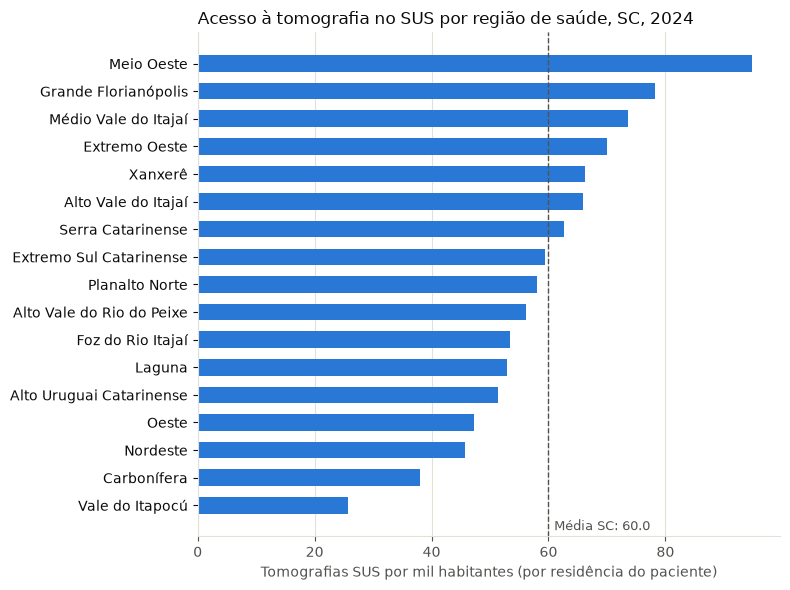

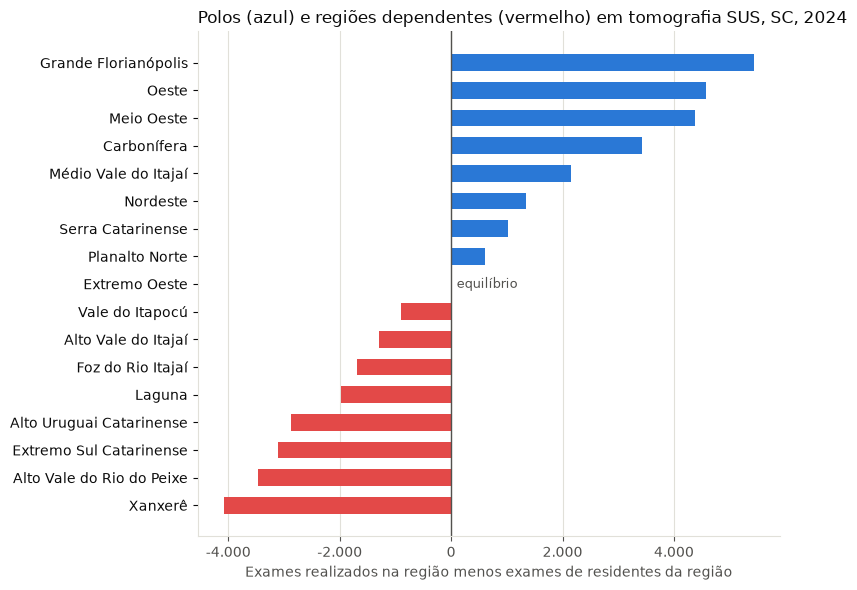

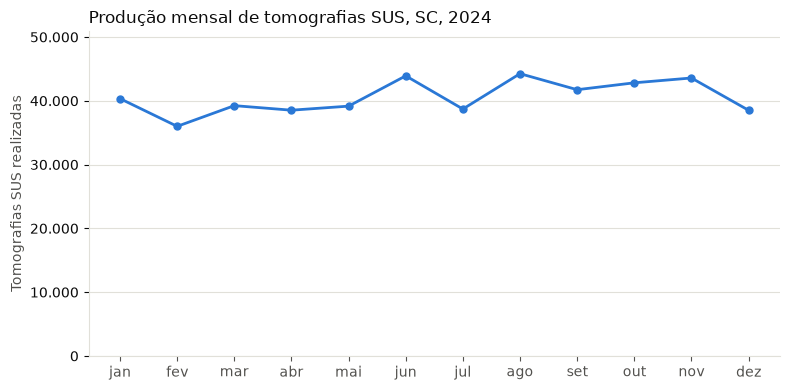

Média SC: 60.0 tomografias SUS por mil habitantes


In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

FIGURAS = Path("../figuras")
FIGURAS.mkdir(exist_ok=True)

AZUL, VERMELHO = "#2a78d6", "#e34948"
TEXTO, TEXTO_SUAVE, GRADE = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRADE, "axes.labelcolor": TEXTO_SUAVE,
    "xtick.color": TEXTO_SUAVE, "ytick.color": TEXTO,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})
milhar = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

# Recalcula a tabela por região usando só exames realizados em 2024
def exames_por_regiao(coluna_municipio):
    return (sia24.merge(mapa_mun, left_on=coluna_municipio, right_on="CODUFMUN", how="left")
            .groupby("regiao_saude")["PA_QTDAPR"].sum())

exames24 = pd.DataFrame({
    "exames_realizados": exames_por_regiao("PA_UFMUN"),
    "exames_residentes": exames_por_regiao("PA_MUNPCN"),
}).join(pop_regiao)
exames24["residentes_por_mil"] = exames24["exames_residentes"] / exames24["populacao"] * 1000
exames24["saldo"] = exames24["exames_realizados"] - exames24["exames_residentes"]
media_sc = exames24["exames_residentes"].sum() / exames24["populacao"].sum() * 1000

# Gráfico 1: acesso por região
dados = exames24.sort_values("residentes_por_mil")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(dados.index, dados["residentes_por_mil"], color=AZUL, height=0.6)
ax.axvline(media_sc, color=TEXTO_SUAVE, linestyle="--", linewidth=1)
ax.text(media_sc + 1, -0.9, f"Média SC: {media_sc:.1f}", color=TEXTO_SUAVE, fontsize=9)
ax.set_xlabel("Tomografias SUS por mil habitantes (por residência do paciente)")
ax.set_title("Acesso à tomografia no SUS por região de saúde, SC, 2024", loc="left", color=TEXTO)
ax.grid(axis="x", color=GRADE, linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURAS / "01_acesso_por_regiao.png", dpi=150)
plt.show()

# Gráfico 2: polos e regiões dependentes
dados = exames24.sort_values("saldo")
cores = [AZUL if valor > 0 else VERMELHO for valor in dados["saldo"]]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(dados.index, dados["saldo"], color=cores, height=0.6)
ax.axvline(0, color=TEXTO_SUAVE, linewidth=1)
ax.xaxis.set_major_formatter(milhar)
ax.set_xlabel("Exames realizados na região menos exames de residentes da região")
ax.set_title("Polos (azul) e regiões dependentes (vermelho) em tomografia SUS, SC, 2024",
             loc="left", color=TEXTO)
ax.grid(axis="x", color=GRADE, linewidth=0.8)
ax.set_axisbelow(True)
ax.text(100, list(dados.index).index("Extremo Oeste"), "equilíbrio", va="center", color=TEXTO_SUAVE, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "02_polos_e_dependentes.png", dpi=150)
plt.show()

# Gráfico 3: evolução mensal
mensal = sia24.groupby("PA_CMP")["PA_QTDAPR"].sum()
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(meses, mensal.values, color=AZUL, linewidth=2, marker="o", markersize=5)
ax.set_ylim(0, mensal.max() * 1.15)
ax.yaxis.set_major_formatter(milhar)
ax.set_ylabel("Tomografias SUS realizadas")
ax.set_title("Produção mensal de tomografias SUS, SC, 2024", loc="left", color=TEXTO)
ax.grid(axis="y", color=GRADE, linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURAS / "03_producao_mensal.png", dpi=150)
plt.show()

# Salva a tabela final de indicadores para o README
final = indicadores[["QT_EXIST", "QT_SUS_AJUST", "populacao", "tc_sus_ajust_por_100mil"]].join(
    exames24[["exames_residentes", "residentes_por_mil", "saldo"]])
final.round(2).to_csv(PASTA / "indicadores_por_regiao_2024.csv", encoding="utf-8-sig")
print(f"Média SC: {media_sc:.1f} tomografias SUS por mil habitantes")